# Analysis of batch run on paired TI task
The purpose of this notebook is to know the distribution of testing accuracies on the paired transitive inference task.

## Imports

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
results = pd.read_csv('../../data/paired_ti_results.csv')
results.head()

,seed,self_attention_acc,relational_attention_acc,self_attention_linear_acc,relational_attention_linear_acc
0,0,0.324,0.823,1.000,1.000
1,1,0.486,0.920,0.917,0.157
2,2,0.336,0.754,0.498,0.157
3,3,0.668,1.000,0.493,0.182
4,4,0.230,1.000,1.000,0.514


## Perform statistics

In [3]:
# Extract accuracy columns
self_acc = results['self_attention_acc'].values
rel_acc = results['relational_attention_acc'].values

In [4]:
# Mean
mean_self = np.mean(self_acc)
mean_rel = np.mean(rel_acc)

# Standard error (SEM = std / sqrt(n))
sem_self = np.std(self_acc, ddof=1) / np.sqrt(len(self_acc))
sem_rel = np.std(rel_acc, ddof=1) / np.sqrt(len(rel_acc))

print("Self attention: mean =", mean_self, "SEM =", sem_self)
print("Relational attention: mean =", mean_rel, "SEM =", sem_rel)

Self attention: mean = 0.4047666666666668 SEM = 0.030024652067938546
Relational attention: mean = 0.7076666666666667 SEM = 0.04283261549557266


In [5]:
# Wilcoxon signed-rank test (non-parametric paired test)
w_stat, w_p_value = stats.wilcoxon(rel_acc, self_acc)

print("Wilcoxon signed-rank test:")
print("W =", w_stat)
print("p =", w_p_value)

Wilcoxon signed-rank test:
W = 26.0
p = 2.160855490180634e-05


## Violin plot without linear models

In [6]:
# Melt into long format for Seaborn
df_long = results.melt(
    value_vars=['self_attention_acc', 'relational_attention_acc'],
    var_name='model',
    value_name='accuracy'
)

/var/folders/0v/sg01g0jd48j1x5lmw3jl63cc0000gn/T/ipykernel_19573/4111498032.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


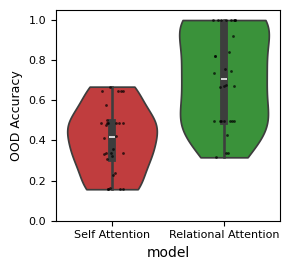

In [7]:
plt.figure(figsize=(3, 2.8))

sns.violinplot(
    data=df_long,
    x='model',
    y='accuracy',
    inner='box',
    palette=['tab:red', 'tab:green'],
    cut=0
)

# (Optional) overlay scatter points for each seed
sns.stripplot(
    data=df_long,
    x='model',
    y='accuracy',
    color='black',
    size=2,
    alpha=0.7
)

plt.ylabel('OOD Accuracy', fontsize=9)
plt.xticks([0, 1], ['Self Attention', 'Relational Attention'], fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(0, 1.05)

plt.tight_layout()
plt.savefig('../../results/paired_ti_violin.svg', dpi=300, bbox_inches='tight')
plt.show()

## Violin plot with linear models

In [8]:
# Melt into long format for Seaborn
df_long = results.melt(
    value_vars=['self_attention_acc', 'relational_attention_acc', 'self_attention_linear_acc', 'relational_attention_linear_acc'],
    var_name='model',
    value_name='accuracy'
)

/var/folders/0v/sg01g0jd48j1x5lmw3jl63cc0000gn/T/ipykernel_19573/1412621986.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


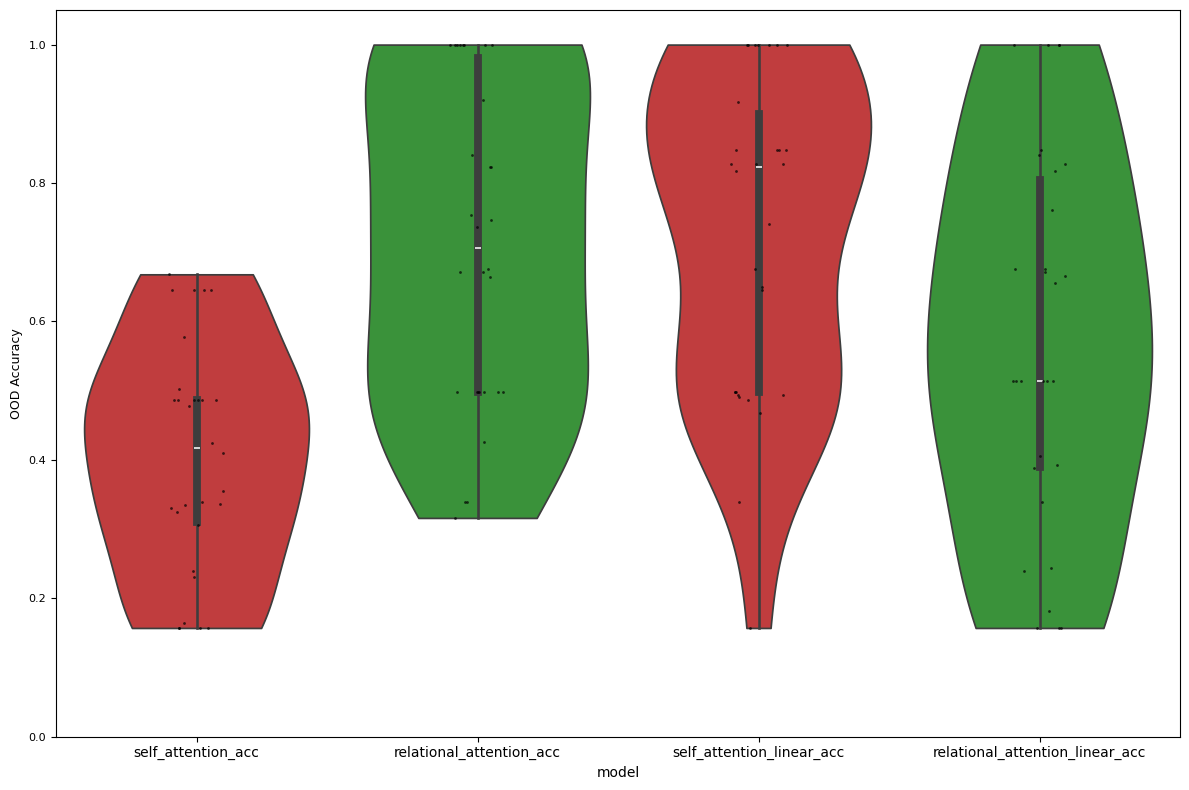

In [9]:
plt.figure(figsize=(12, 8))

sns.violinplot(
    data=df_long,
    x='model',
    y='accuracy',
    inner='box',
    palette=['tab:red', 'tab:green', 'tab:red', 'tab:green', ],
    cut=0
)

# (Optional) overlay scatter points for each seed
sns.stripplot(
    data=df_long,
    x='model',
    y='accuracy',
    color='black',
    size=2,
    alpha=0.7
)

plt.ylabel('OOD Accuracy', fontsize=9)
plt.yticks(fontsize=8)
plt.ylim(0, 1.05)

plt.tight_layout()
plt.show()